# Northstar Retail | FP&A and Treasury Analytics
**Synthetic case study | 2025–2027**

Reproducible Python + SQLite analysis of product profitability, 2026 budget variance, EBITDA, approximate working capital, and a 13-week cash forecast. The exported dashboard is built separately in Google Looker Studio.

**Important limitations:** Synthetic transaction-level data has uniformly random order dates, so it is not calibrated to realistic retail seasonality. Budgeting and operating costs use illustrative assumptions. The direct cash forecast approximates purchases as COGS, October supplier obligations using weekly COGS, and four-week supplier settlement; it does not reconcile exactly with the monthly working-capital model. It excludes taxes, capex and financing. The two cash forecast approaches should not be treated as identical.

## 1. Generate synthetic data and create SQLite tables

In [1]:
import pandas as pd
import numpy as np
import sqlite3

rng = np.random.default_rng(42)

# Fictional retail products
products = pd.DataFrame({
    "sku": ["LAP", "MON", "KEY", "MOU", "HDP", "CAM"],
    "product": [
        "Laptop", "Monitor", "Keyboard",
        "Mouse", "Headphones", "Webcam"
    ],
    "unit_price": [900, 250, 80, 40, 120, 95],
    "unit_cost": [650, 160, 42, 18, 65, 55]
})

# Generate 12,000 fictional transactions
n = 12000

sales = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "date": rng.choice(
        pd.date_range("2025-01-01", "2026-10-31"),
        size=n
    ),
    "sku": rng.choice(
        products["sku"],
        size=n
    ),
    "quantity": rng.integers(1, 5, size=n),
    "discount": rng.choice(
        [0, 0.05, 0.10, 0.15],
        size=n
    )
})

sales = sales.merge(products, on="sku")

# Calculate transaction economics
sales["revenue"] = (
    sales["quantity"]
    * sales["unit_price"]
    * (1 - sales["discount"])
)

sales["cogs"] = (
    sales["quantity"] * sales["unit_cost"]
)

sales["gross_profit"] = (
    sales["revenue"] - sales["cogs"]
)

sales = sales.sort_values("date")

# Create SQLite database
conn = sqlite3.connect("retail_finance.db")

sales.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

products.to_sql(
    "products",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully!")
print(f"Transactions: {len(sales):,}")
print(sales.head())


Database created successfully!
Transactions: 12,000
      order_id       date  sku  ...  revenue  cogs gross_profit
6301      6302 2025-01-01  KEY  ...     72.0    42         30.0
7005      7006 2025-01-01  MOU  ...     72.0    36         36.0
9283      9284 2025-01-01  CAM  ...    180.5   110         70.5
5082      5083 2025-01-01  MOU  ...     80.0    36         44.0
1487      1488 2025-01-01  LAP  ...   2295.0  1950        345.0

[5 rows x 11 columns]


## 2. SQL profitability analysis

In [2]:
query = """
SELECT
    strftime('%Y-%m', date) AS month,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(cogs), 2) AS cogs,
    ROUND(SUM(gross_profit), 2) AS gross_profit,
    ROUND(
        100.0 * SUM(gross_profit)
        / NULLIF(SUM(revenue), 0), 2
    ) AS gross_margin_pct

FROM sales

GROUP BY strftime('%Y-%m', date)
ORDER BY month;
"""

monthly_results = pd.read_sql_query(query, conn)

display(monthly_results)


,month,revenue,cogs,gross_profit,gross_margin_pct
0,2025-01,285079.50,204284.0,80795.50,28.34
1,2025-02,293075.00,212712.0,80363.00,27.42
2,2025-03,304829.75,217193.0,87636.75,28.75
3,2025-04,312919.00,227738.0,85181.00,27.22
4,2025-05,296183.75,212795.0,83388.75,28.15
5,2025-06,294588.50,211050.0,83538.50,28.36
6,2025-07,379594.00,275036.0,104558.00,27.54
7,2025-08,322984.50,233073.0,89911.50,27.84
8,2025-09,268405.25,192100.0,76305.25,28.43
9,2025-10,358962.25,259607.0,99355.25,27.68


In [3]:
query = """
SELECT
    product,
    SUM(quantity) AS units_sold,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(cogs), 2) AS cogs,
    ROUND(SUM(gross_profit), 2) AS gross_profit,
    ROUND(
        100.0 * SUM(gross_profit) /
        NULLIF(SUM(revenue), 0), 2
    ) AS gross_margin_pct
FROM sales
GROUP BY product
ORDER BY gross_profit DESC;
"""

product_results = pd.read_sql_query(query, conn)

display(product_results)


,product,units_sold,revenue,cogs,gross_profit,gross_margin_pct
0,Laptop,5136,4280445.00,3338400.0,942045.00,22.01
1,Monitor,4847,1121762.50,775520.0,346242.50,30.87
2,Headphones,5136,569556.00,333840.0,235716.00,41.39
3,Webcam,4951,435038.25,272305.0,162733.25,37.41
4,Keyboard,5056,374212.00,212352.0,161860.00,43.25
5,Mouse,4956,183550.00,89208.0,94342.00,51.40


In [4]:
# Calculate contribution to total revenue and profit
product_results["revenue_share_pct"] = (
    product_results["revenue"]
    / product_results["revenue"].sum() * 100
)

product_results["profit_share_pct"] = (
    product_results["gross_profit"]
    / product_results["gross_profit"].sum() * 100
)

display(
    product_results[[
        "product",
        "revenue_share_pct",
        "profit_share_pct",
        "gross_margin_pct"
    ]].round(2)
)


,product,revenue_share_pct,profit_share_pct,gross_margin_pct
0,Laptop,61.46,48.49,22.01
1,Monitor,16.11,17.82,30.87
2,Headphones,8.18,12.13,41.39
3,Webcam,6.25,8.38,37.41
4,Keyboard,5.37,8.33,43.25
5,Mouse,2.64,4.86,51.40


## 3. Monthly 2026 budget vs actual management P&L

In [5]:
# Start with monthly financial data
monthly_pnl = monthly_results.copy()

monthly_pnl["month"] = pd.to_datetime(
    monthly_pnl["month"]
)

monthly_pnl["year"] = monthly_pnl["month"].dt.year
monthly_pnl["month_number"] = monthly_pnl["month"].dt.month

# Separate historical and actual results
historical = monthly_pnl[
    monthly_pnl["year"] == 2025
][["month_number", "revenue", "cogs", "gross_profit"]]

actuals = monthly_pnl[
    monthly_pnl["year"] == 2026
][["month_number", "revenue", "cogs", "gross_profit"]]

# Combine historical and actual data
management_pnl = actuals.merge(
    historical,
    on="month_number",
    suffixes=("_actual", "_2025")
)

# Revenue and gross profit budgets
management_pnl["revenue_budget"] = (
    management_pnl["revenue_2025"] * 1.10
)

management_pnl["cogs_budget"] = (
    management_pnl["cogs_2025"] * 1.10
)

management_pnl["gp_budget"] = (
    management_pnl["revenue_budget"]
    - management_pnl["cogs_budget"]
)

# Operating expense budgets
management_pnl["opex_budget"] = (
    42000 + 14000
    + management_pnl["revenue_budget"] * 0.04
)

# Actual operating expenses
management_pnl["opex_actual"] = (
    42000 + 17000
    + management_pnl["revenue_actual"] * 0.045
)

# EBITDA
management_pnl["ebitda_budget"] = (
    management_pnl["gp_budget"]
    - management_pnl["opex_budget"]
)

management_pnl["ebitda_actual"] = (
    management_pnl["gross_profit_actual"]
    - management_pnl["opex_actual"]
)

# Performance variances
management_pnl["revenue_variance"] = (
    management_pnl["revenue_actual"]
    - management_pnl["revenue_budget"]
)

management_pnl["ebitda_variance"] = (
    management_pnl["ebitda_actual"]
    - management_pnl["ebitda_budget"]
)

# Display management report
report = management_pnl[[
    "month_number",
    "revenue_budget",
    "revenue_actual",
    "revenue_variance",
    "ebitda_budget",
    "ebitda_actual",
    "ebitda_variance"
]]

display(report.round(2))


,month_number,revenue_budget,revenue_actual,revenue_variance,ebitda_budget,ebitda_actual,ebitda_variance
0,1,313587.45,328795.25,15207.80,20331.55,16430.46,-3901.09
1,2,322382.50,282077.25,-40305.25,19504.00,6340.77,-13163.23
2,3,335312.73,327994.25,-7318.48,26987.92,17986.51,-9001.41
3,4,344210.90,292485.25,-51725.65,23930.66,8725.41,-15205.25
4,5,325802.12,340498.25,14696.12,22695.54,21426.83,-1268.71
5,6,324047.35,322165.50,-1881.85,22930.46,16842.05,-6088.40
6,7,417553.40,364416.50,-53136.90,42311.66,22739.76,-19571.91
7,8,355282.95,270288.00,-84994.95,28691.33,6179.04,-22512.29
8,9,295245.78,303250.75,8004.97,16125.94,12606.47,-3519.48
9,10,394858.48,336348.00,-58510.48,37496.44,19260.34,-18236.10


## 4. August revenue diagnostics and variance bridges

In [6]:
query = """
SELECT
    product,
    ROUND(SUM(
        CASE WHEN strftime('%Y', date) = '2025'
        THEN revenue ELSE 0 END
    ), 2) AS revenue_2025,

    ROUND(SUM(
        CASE WHEN strftime('%Y', date) = '2026'
        THEN revenue ELSE 0 END
    ), 2) AS revenue_2026

FROM sales
WHERE strftime('%m', date) = '08'
GROUP BY product
ORDER BY product;
"""

august_analysis = pd.read_sql_query(query, conn)

august_analysis["change"] = (
    august_analysis["revenue_2026"]
    - august_analysis["revenue_2025"]
)

august_analysis["change_pct"] = (
    august_analysis["change"]
    / august_analysis["revenue_2025"] * 100
)

display(august_analysis.round(2))


,product,revenue_2025,revenue_2026,change,change_pct
0,Headphones,24732.0,26652.0,1920.0,7.76
1,Keyboard,16432.0,16404.0,-28.0,-0.17
2,Laptop,196290.0,162855.0,-33435.0,-17.03
3,Monitor,52825.0,40462.5,-12362.5,-23.40
4,Mouse,9554.0,8116.0,-1438.0,-15.05
5,Webcam,23151.5,15798.5,-7353.0,-31.76


In [7]:
august_analysis["budget_2026"] = (
    august_analysis["revenue_2025"] * 1.10
)

august_analysis["budget_variance"] = (
    august_analysis["revenue_2026"]
    - august_analysis["budget_2026"]
)

august_analysis["shortfall_share_pct"] = (
    august_analysis["budget_variance"]
    / august_analysis["budget_variance"].sum()
    * 100
)

display(
    august_analysis[[
        "product",
        "budget_2026",
        "revenue_2026",
        "budget_variance",
        "shortfall_share_pct"
    ]].sort_values("budget_variance").round(2)
)


,product,budget_2026,revenue_2026,budget_variance,shortfall_share_pct
2,Laptop,215919.00,162855.0,-53064.00,62.43
3,Monitor,58107.50,40462.5,-17645.00,20.76
5,Webcam,25466.65,15798.5,-9668.15,11.37
4,Mouse,10509.40,8116.0,-2393.40,2.82
1,Keyboard,18075.20,16404.0,-1671.20,1.97
0,Headphones,27205.20,26652.0,-553.20,0.65


In [8]:
query = """
SELECT
    strftime('%Y', date) AS year,
    SUM(quantity) AS units_sold,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(
        SUM(revenue) * 1.0 / SUM(quantity), 2
    ) AS avg_selling_price
FROM sales
WHERE product = 'Laptop'
  AND strftime('%m', date) = '08'
GROUP BY strftime('%Y', date)
ORDER BY year;
"""

laptop_analysis = pd.read_sql_query(query, conn)

display(laptop_analysis)


,year,units_sold,revenue,avg_selling_price
0,2025,236,196290.0,831.74
1,2026,194,162855.0,839.46


In [9]:
# August 2025 baseline
units_2025 = 236
revenue_2025 = 196290

# August 2026 actual
units_2026 = 194
revenue_2026 = 162855

# Budget assumptions
budget_units = units_2025 * 1.10
base_price = revenue_2025 / units_2025
actual_price = revenue_2026 / units_2026

budget_revenue = budget_units * base_price

# Revenue variance decomposition
volume_variance = (
    units_2026 - budget_units
) * base_price

price_variance = (
    actual_price - base_price
) * units_2026

total_variance = volume_variance + price_variance

print(f"Budget revenue: €{budget_revenue:,.2f}")
print(f"Volume variance: €{volume_variance:,.2f}")
print(f"Price variance: €{price_variance:,.2f}")
print(f"Total variance: €{total_variance:,.2f}")


Budget revenue: €215,919.00
Volume variance: €-54,561.97
Price variance: €1,497.97
Total variance: €-53,064.00


In [10]:
query = """
SELECT
    strftime('%Y', date) AS year,
    ROUND(SUM(revenue), 2) AS revenue,
    ROUND(SUM(cogs), 2) AS cogs,
    ROUND(SUM(gross_profit), 2) AS gross_profit
FROM sales
WHERE strftime('%m', date) = '08'
GROUP BY strftime('%Y', date)
ORDER BY year;
"""

august_profit = pd.read_sql_query(query, conn)

# Budget assumes 10% growth from August 2025
budget_revenue = august_profit.loc[0, "revenue"] * 1.10
budget_cogs = august_profit.loc[0, "cogs"] * 1.10
budget_gp = budget_revenue - budget_cogs

# August 2026 actual results
actual_revenue = august_profit.loc[1, "revenue"]
actual_cogs = august_profit.loc[1, "cogs"]
actual_gp = august_profit.loc[1, "gross_profit"]

profit_comparison = pd.DataFrame({
    "Metric": ["Revenue", "COGS", "Gross Profit"],
    "Budget": [budget_revenue, budget_cogs, budget_gp],
    "Actual": [actual_revenue, actual_cogs, actual_gp]
})

profit_comparison["Variance"] = (
    profit_comparison["Actual"]
    - profit_comparison["Budget"]
)

display(profit_comparison.round(2))


,Metric,Budget,Actual,Variance
0,Revenue,355282.95,270288.0,-84994.95
1,COGS,256380.30,192946.0,-63434.30
2,Gross Profit,98902.65,77342.0,-21560.65


In [11]:
# Gross margin analysis
budget_margin = budget_gp / budget_revenue
actual_margin = actual_gp / actual_revenue

# Decompose the gross profit variance
revenue_effect = (
    actual_revenue - budget_revenue
) * budget_margin

margin_effect = (
    actual_margin - budget_margin
) * actual_revenue

gp_variance = revenue_effect + margin_effect

print(f"Budget gross margin: {budget_margin:.2%}")
print(f"Actual gross margin: {actual_margin:.2%}")

print(f"\nRevenue effect: €{revenue_effect:,.2f}")
print(f"Margin effect: €{margin_effect:,.2f}")
print(f"Total GP variance: €{gp_variance:,.2f}")


Budget gross margin: 27.84%
Actual gross margin: 28.61%

Revenue effect: €-23,660.65
Margin effect: €2,100.00
Total GP variance: €-21,560.65


In [12]:
# August operating expense assumptions
salary_budget = 42000
salary_actual = 42000

marketing_budget = 14000
marketing_actual = 17000

fulfillment_budget = budget_revenue * 0.04
fulfillment_actual = actual_revenue * 0.045

# Total operating expenses
budget_opex = (
    salary_budget
    + marketing_budget
    + fulfillment_budget
)

actual_opex = (
    salary_actual
    + marketing_actual
    + fulfillment_actual
)

# EBITDA
budget_ebitda = budget_gp - budget_opex
actual_ebitda = actual_gp - actual_opex

# Management P&L
pnl = pd.DataFrame({
    "Metric": [
        "Revenue",
        "COGS",
        "Gross Profit",
        "Operating Expenses",
        "EBITDA"
    ],
    "Budget": [
        budget_revenue,
        budget_cogs,
        budget_gp,
        budget_opex,
        budget_ebitda
    ],
    "Actual": [
        actual_revenue,
        actual_cogs,
        actual_gp,
        actual_opex,
        actual_ebitda
    ]
})

pnl["Variance"] = pnl["Actual"] - pnl["Budget"]

display(pnl.round(2))


,Metric,Budget,Actual,Variance
0,Revenue,355282.95,270288.00,-84994.95
1,COGS,256380.30,192946.00,-63434.30
2,Gross Profit,98902.65,77342.00,-21560.65
3,Operating Expenses,70211.32,71162.96,951.64
4,EBITDA,28691.33,6179.04,-22512.29


In [13]:
# Calculate EBITDA margins
budget_ebitda_margin = (
    budget_ebitda / budget_revenue * 100
)

actual_ebitda_margin = (
    actual_ebitda / actual_revenue * 100
)

margin_variance = (
    actual_ebitda_margin - budget_ebitda_margin
)

print(f"Budget EBITDA margin: {budget_ebitda_margin:.2f}%")
print(f"Actual EBITDA margin: {actual_ebitda_margin:.2f}%")
print(f"Margin variance: {margin_variance:.2f} pp")


Budget EBITDA margin: 8.08%
Actual EBITDA margin: 2.29%
Margin variance: -5.79 pp


## 5. Working capital and historic operating cash flow
Assume DIO 45 days, DPO 30 days, cash customers, and a 30-day month for estimated balances. January operating cash flow is left unknown because the December 2025 opening balance was not modelled.

In [14]:
# Working capital assumptions
dio = 45
dpo = 30

# Use the actual monthly COGS from our P&L
working_capital = management_pnl[[
    "month_number", "cogs_actual"
]].copy()

# Simplified 30-day month convention
working_capital["inventory"] = (
    working_capital["cogs_actual"] / 30 * dio
)

working_capital["accounts_payable"] = (
    working_capital["cogs_actual"] / 30 * dpo
)

# Simplified operating working capital
# Assume customers pay immediately
working_capital["net_working_capital"] = (
    working_capital["inventory"]
    - working_capital["accounts_payable"]
)

display(working_capital.round(2))


,month_number,cogs_actual,inventory,accounts_payable,net_working_capital
0,1,238569.0,357853.5,238569.0,119284.5
1,2,204043.0,306064.5,204043.0,102021.5
2,3,236248.0,354372.0,236248.0,118124.0
3,4,211598.0,317397.0,211598.0,105799.0
4,5,244749.0,367123.5,244749.0,122374.5
5,6,231826.0,347739.0,231826.0,115913.0
6,7,266278.0,399417.0,266278.0,133139.0
7,8,192946.0,289419.0,192946.0,96473.0
8,9,217998.0,326997.0,217998.0,108999.0
9,10,242952.0,364428.0,242952.0,121476.0


In [15]:
# Combine monthly P&L with working capital
cash_flow = management_pnl[[
    "month_number",
    "ebitda_actual"
]].merge(
    working_capital[[
        "month_number",
        "inventory",
        "accounts_payable",
        "net_working_capital"
    ]],
    on="month_number"
)

# Changes in working capital
cash_flow["change_nwc"] = (
    cash_flow["net_working_capital"].diff()
)

# January requires a December 2025 opening balance.
# Leave January change unknown rather than assume zero.
cash_flow["operating_cash_flow"] = (
    cash_flow["ebitda_actual"]
    - cash_flow["change_nwc"]
)

# Display monthly results
display(cash_flow.round(2))


,month_number,ebitda_actual,inventory,accounts_payable,net_working_capital,change_nwc,operating_cash_flow
0,1,16430.46,357853.5,238569.0,119284.5,NaN,NaN
1,2,6340.77,306064.5,204043.0,102021.5,-17263.0,23603.77
2,3,17986.51,354372.0,236248.0,118124.0,16102.5,1884.01
3,4,8725.41,317397.0,211598.0,105799.0,-12325.0,21050.41
4,5,21426.83,367123.5,244749.0,122374.5,16575.5,4851.33
5,6,16842.05,347739.0,231826.0,115913.0,-6461.5,23303.55
6,7,22739.76,399417.0,266278.0,133139.0,17226.0,5513.76
7,8,6179.04,289419.0,192946.0,96473.0,-36666.0,42845.04
8,9,12606.47,326997.0,217998.0,108999.0,12526.0,80.47
9,10,19260.34,364428.0,242952.0,121476.0,12477.0,6783.34


In [16]:
# Assumed opening cash at January 31, 2026
opening_cash = 250000

# February to October cash flows
cash_balance = cash_flow[
    cash_flow["month_number"] >= 2
].copy()

# Cumulative operating cash flow
cash_balance["cumulative_cash_flow"] = (
    cash_balance["operating_cash_flow"].cumsum()
)

# Closing cash balance
cash_balance["closing_cash"] = (
    opening_cash
    + cash_balance["cumulative_cash_flow"]
)

display(
    cash_balance[[
        "month_number",
        "operating_cash_flow",
        "closing_cash"
    ]].round(2)
)


,month_number,operating_cash_flow,closing_cash
1,2,23603.77,273603.77
2,3,1884.01,275487.78
3,4,21050.41,296538.20
4,5,4851.33,301389.53
5,6,23303.55,324693.08
6,7,5513.76,330206.84
7,8,42845.04,373051.88
8,9,80.47,373132.34
9,10,6783.34,379915.68


## 6. November–December monthly forecast
10% annual revenue growth, 28% gross margin, fixed operating costs and a simple DIO/DPO balance estimate.

In [17]:
# Get historical November and December sales
historical_q4 = monthly_pnl[
    (monthly_pnl["year"] == 2025)
    & (monthly_pnl["month_number"].isin([11, 12]))
].copy()

forecast = pd.DataFrame({
    "month_number": historical_q4["month_number"],
    "revenue_2025": historical_q4["revenue"]
})

# Forecast assumptions
forecast["revenue"] = forecast["revenue_2025"] * 1.10
forecast["cogs"] = forecast["revenue"] * 0.72
forecast["gross_profit"] = forecast["revenue"] - forecast["cogs"]

forecast["opex"] = (
    42000 + 17000
    + forecast["revenue"] * 0.045
)

forecast["ebitda"] = (
    forecast["gross_profit"] - forecast["opex"]
)

# Forecast working capital balances
forecast["inventory"] = forecast["cogs"] / 30 * 45
forecast["accounts_payable"] = forecast["cogs"] / 30 * 30
forecast["nwc"] = (
    forecast["inventory"] - forecast["accounts_payable"]
)

# October actual working capital
previous_nwc = working_capital.loc[
    working_capital["month_number"] == 10,
    "net_working_capital"
].iloc[0]

forecast = forecast.sort_values("month_number").reset_index(drop=True)

forecast["change_nwc"] = (
    forecast["nwc"]
    - forecast["nwc"].shift(1).fillna(previous_nwc)
)

forecast["operating_cash_flow"] = (
    forecast["ebitda"] - forecast["change_nwc"]
)

# Start from October closing cash
october_cash = cash_balance["closing_cash"].iloc[-1]

forecast["closing_cash"] = (
    october_cash + forecast["operating_cash_flow"].cumsum()
)

display(forecast[[
    "month_number",
    "revenue",
    "ebitda",
    "change_nwc",
    "operating_cash_flow",
    "closing_cash"
]].round(2))


,month_number,revenue,ebitda,change_nwc,operating_cash_flow,closing_cash
0,11,343868.52,21809.10,2316.67,19492.43,399408.12
1,12,403717.05,35873.51,21545.47,14328.04,413736.15


In [18]:
# Treasury liquidity assumptions
minimum_cash = 150000

forecast["minimum_cash"] = minimum_cash

forecast["liquidity_headroom"] = (
    forecast["closing_cash"] - minimum_cash
)

forecast["liquidity_status"] = np.where(
    forecast["liquidity_headroom"] >= 0,
    "Sufficient",
    "Shortfall"
)

display(forecast[[
    "month_number",
    "closing_cash",
    "minimum_cash",
    "liquidity_headroom",
    "liquidity_status"
]].round(2))


,month_number,closing_cash,minimum_cash,liquidity_headroom,liquidity_status
0,11,399408.12,150000,249408.12,Sufficient
1,12,413736.15,150000,263736.15,Sufficient


## 7. Direct 13-week cash flow forecast
Use daily proration of monthly inputs, Monday–Sunday weeks, a four-week lag for supplier payments, and an opening cash estimate at end October. Compared with the monthly indirect method, this is a different modelling approach.

In [19]:
# Forecast January 2027 revenue at 10% above January 2026 actual
january_revenue = management_pnl.loc[management_pnl["month_number"] == 1, "revenue_actual"].iloc[0] * 1.10
monthly_assumptions = forecast.set_index("month_number")
monthly_revenue = {11: monthly_assumptions.loc[11, "revenue"], 12: monthly_assumptions.loc[12, "revenue"], 1: january_revenue}


In [20]:
# Build daily assumptions, then aggregate into weeks
daily_dates = pd.date_range(
    "2026-11-02", "2027-01-31", freq="D"
)

daily = pd.DataFrame({"date": daily_dates})
daily["month"] = daily["date"].dt.month
daily["days_in_month"] = daily["date"].dt.days_in_month

# Spread each month's forecast across calendar days
daily["revenue"] = (
    daily["month"].map(monthly_revenue)
    / daily["days_in_month"]
)

daily["purchases"] = daily["revenue"] * 0.72
daily["fulfillment"] = daily["revenue"] * 0.045

daily["payroll_admin"] = 42000 / daily["days_in_month"]
daily["marketing"] = 17000 / daily["days_in_month"]

# Group into Monday-Sunday weeks
daily["week_start"] = (
    daily["date"]
    - pd.to_timedelta(daily["date"].dt.weekday, unit="D")
)

weekly_forecast = daily.groupby(
    "week_start", as_index=False
).agg(
    customer_receipts=("revenue", "sum"),
    inventory_purchases=("purchases", "sum"),
    fulfillment=("fulfillment", "sum"),
    payroll_admin=("payroll_admin", "sum"),
    marketing=("marketing", "sum")
)

# October purchases used as a proxy for payments
# due in the first four forecast weeks
october_cogs = working_capital.loc[
    working_capital["month_number"] == 10,
    "cogs_actual"
].iloc[0]

october_weekly_purchases = october_cogs / 31 * 7

# Payments occur four weeks after purchases
weekly_forecast["supplier_payments"] = (
    weekly_forecast["inventory_purchases"].shift(4)
    .fillna(october_weekly_purchases)
)

display(weekly_forecast.round(2))


,week_start,customer_receipts,inventory_purchases,fulfillment,payroll_admin,marketing,supplier_payments
0,2026-11-02,80235.99,57769.91,3610.62,9800.00,3966.67,54860.13
1,2026-11-09,80235.99,57769.91,3610.62,9800.00,3966.67,54860.13
2,2026-11-16,80235.99,57769.91,3610.62,9800.00,3966.67,54860.13
3,2026-11-23,80235.99,57769.91,3610.62,9800.00,3966.67,54860.13
4,2026-11-30,89601.07,64512.77,4032.05,9529.03,3856.99,57769.91
5,2026-12-07,91161.91,65636.58,4102.29,9483.87,3838.71,57769.91
6,2026-12-14,91161.91,65636.58,4102.29,9483.87,3838.71,57769.91
7,2026-12-21,91161.91,65636.58,4102.29,9483.87,3838.71,57769.91
8,2026-12-28,87093.31,62707.18,3919.20,9483.87,3838.71,64512.77
9,2027-01-04,81668.50,58801.32,3675.08,9483.87,3838.71,65636.58


In [21]:
# Direct cash flow forecast
weekly_forecast["total_payments"] = (
    weekly_forecast["supplier_payments"]
    + weekly_forecast["fulfillment"]
    + weekly_forecast["payroll_admin"]
    + weekly_forecast["marketing"]
)

weekly_forecast["net_cash_flow"] = (
    weekly_forecast["customer_receipts"]
    - weekly_forecast["total_payments"]
)

# October closing cash
opening_cash = round(float(cash_balance["closing_cash"].iloc[-1]), 2)

weekly_forecast["closing_cash"] = (
    opening_cash
    + weekly_forecast["net_cash_flow"].cumsum()
)

weekly_forecast["liquidity_headroom"] = (
    weekly_forecast["closing_cash"] - 150000
)

display(weekly_forecast[[
    "week_start",
    "customer_receipts",
    "supplier_payments",
    "total_payments",
    "net_cash_flow",
    "closing_cash",
    "liquidity_headroom"
]].round(2))


,week_start,customer_receipts,supplier_payments,total_payments,net_cash_flow,closing_cash,liquidity_headroom
0,2026-11-02,80235.99,54860.13,72237.42,7998.57,387914.25,237914.25
1,2026-11-09,80235.99,54860.13,72237.42,7998.57,395912.83,245912.83
2,2026-11-16,80235.99,54860.13,72237.42,7998.57,403911.40,253911.40
3,2026-11-23,80235.99,54860.13,72237.42,7998.57,411909.98,261909.98
4,2026-11-30,89601.07,57769.91,75187.98,14413.09,426323.06,276323.06
5,2026-12-07,91161.91,57769.91,75194.78,15967.14,442290.20,292290.20
6,2026-12-14,91161.91,57769.91,75194.78,15967.14,458257.33,308257.33
7,2026-12-21,91161.91,57769.91,75194.78,15967.14,474224.47,324224.47
8,2026-12-28,87093.31,64512.77,81754.55,5338.76,479563.23,329563.23
9,2027-01-04,81668.50,65636.58,82634.24,-965.74,478597.48,328597.48


## 8. Stress case: December cash receipts 20% below forecast
Payments are held fixed under stress. This is a receipts stress, not an inventory liquidation model.

In [22]:
# Create a stressed cash forecast
stress_daily = daily.copy()

# Reduce December customer receipts by 20%
stress_daily["stressed_receipts"] = np.where(
    (stress_daily["date"].dt.year == 2026)
    & (stress_daily["date"].dt.month == 12),
    stress_daily["revenue"] * 0.80,
    stress_daily["revenue"]
)

# Aggregate revised receipts into weeks
stress_receipts = stress_daily.groupby(
    "week_start"
)["stressed_receipts"].sum()

stress_weekly = weekly_forecast.copy()

stress_weekly["customer_receipts"] = (
    stress_weekly["week_start"].map(stress_receipts)
)

# Keep committed supplier and operating payments unchanged
stress_weekly["net_cash_flow"] = (
    stress_weekly["customer_receipts"]
    - stress_weekly["total_payments"]
)

stress_weekly["closing_cash"] = (
    opening_cash
    + stress_weekly["net_cash_flow"].cumsum()
)

stress_weekly["liquidity_headroom"] = (
    stress_weekly["closing_cash"] - minimum_cash
)

print("BASE CASE")
print(f"Closing cash: €{weekly_forecast['closing_cash'].iloc[-1]:,.2f}")
print(f"Minimum headroom: €{weekly_forecast['liquidity_headroom'].min():,.2f}")

print("\nSTRESS CASE")
print(f"Closing cash: €{stress_weekly['closing_cash'].iloc[-1]:,.2f}")
print(f"Minimum headroom: €{stress_weekly['liquidity_headroom'].min():,.2f}")


BASE CASE
Closing cash: €478,629.65
Minimum headroom: €237,914.25

STRESS CASE
Closing cash: €397,886.24
Minimum headroom: €237,914.25


## 9. Validation, charts and dashboard CSV exports

In [23]:
# Reconciliation checks
assert len(sales) == 12000
assert len(weekly_forecast) == 13
assert abs(management_pnl["revenue_actual"].sum() - 3168319.00) < 0.01
assert abs(management_pnl["ebitda_actual"].sum() - 148537.65) < 0.05
assert abs(weekly_forecast["closing_cash"].iloc[-1] - 478629.65) < 0.05
assert abs(stress_weekly["closing_cash"].iloc[-1] - 397886.24) < 0.05
print("All reconciliation checks passed")
print("Revenue YTD:", round(management_pnl["revenue_actual"].sum(),2))
print("EBITDA YTD:",round(management_pnl["ebitda_actual"].sum(),2))
print("Final base cash:",round(weekly_forecast["closing_cash"].iloc[-1],2))
print("Final stress cash:",round(stress_weekly["closing_cash"].iloc[-1],2))
print("Lowest headroom:",round(weekly_forecast["liquidity_headroom"].min(),2))


All reconciliation checks passed
Revenue YTD: 3168319.0
EBITDA YTD: 148537.65
Final base cash: 478629.65
Final stress cash: 397886.24
Lowest headroom: 237914.25


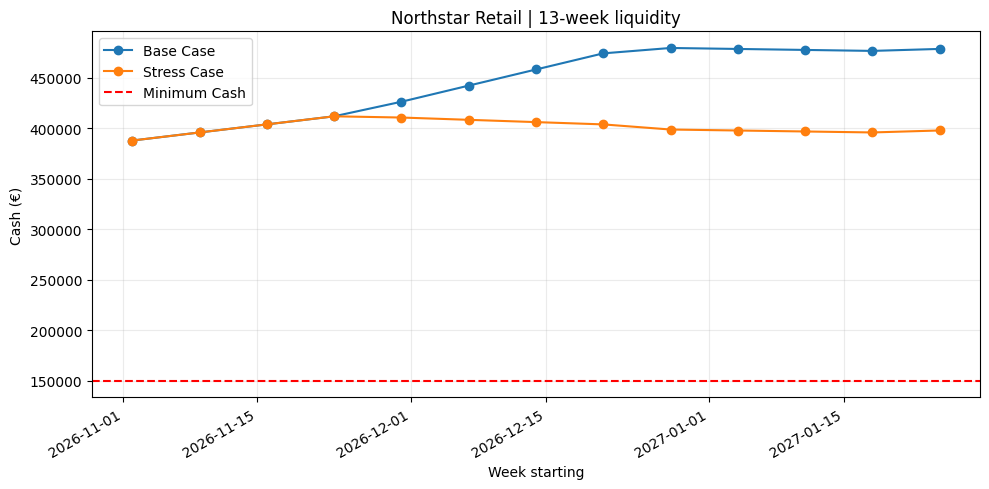

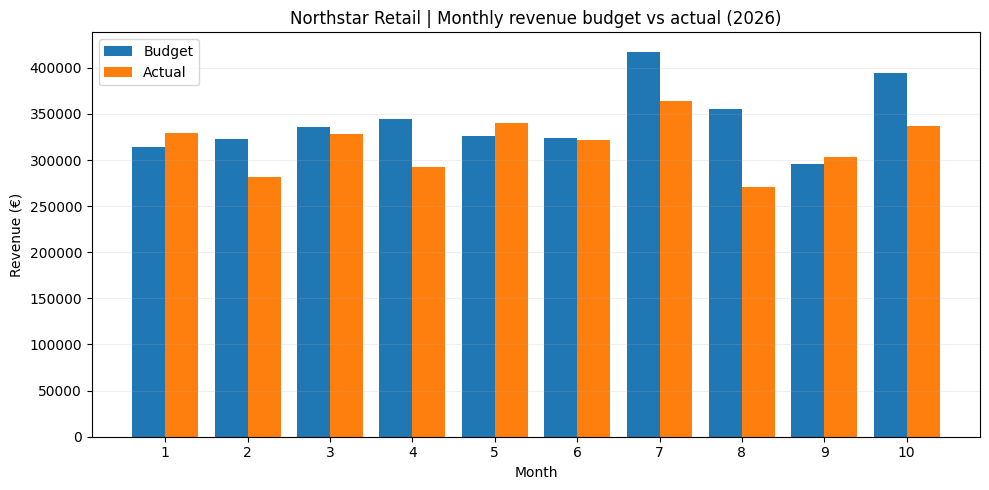

In [24]:
import matplotlib.pyplot as plt
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekly_forecast["week_start"], weekly_forecast["closing_cash"], label="Base Case", marker="o")
ax.plot(stress_weekly["week_start"], stress_weekly["closing_cash"], label="Stress Case", marker="o")
ax.axhline(150000, linestyle="--", color="red", label="Minimum Cash")
ax.set(title="Northstar Retail | 13-week liquidity", ylabel="Cash (€)", xlabel="Week starting")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig("figures/treasury_scenarios.png",dpi=160)
plt.show()

fig, ax=plt.subplots(figsize=(10,5))
ax.bar(management_pnl["month_number"]-.2,management_pnl["revenue_budget"],width=.4,label="Budget")
ax.bar(management_pnl["month_number"]+.2,management_pnl["revenue_actual"],width=.4,label="Actual")
ax.set(title="Northstar Retail | Monthly revenue budget vs actual (2026)",ylabel="Revenue (€)",xlabel="Month")
ax.set_xticks(range(1,11)); ax.legend(); ax.grid(axis="y",alpha=.2); fig.tight_layout()
fig.savefig("figures/revenue_vs_budget.png",dpi=160)
plt.show()


In [25]:
# Export management P&L
management_export = management_pnl.copy()

management_export["date"] = pd.to_datetime(
    "2026-"
    + management_export["month_number"].astype(str).str.zfill(2)
    + "-01"
)

management_export.to_csv(
    "management_pnl.csv",
    index=False
)

# Export product profitability
product_results.to_csv(
    "product_profitability.csv",
    index=False
)

# Export treasury scenarios
treasury_export = weekly_forecast[[
    "week_start",
    "customer_receipts",
    "supplier_payments",
    "total_payments",
    "net_cash_flow",
    "closing_cash",
    "liquidity_headroom"
]].copy()

treasury_export["stress_closing_cash"] = (
    stress_weekly["closing_cash"]
)

treasury_export["stress_headroom"] = (
    stress_weekly["liquidity_headroom"]
)

treasury_export.to_csv(
    "treasury_forecast.csv",
    index=False
)

print("All three CSV files created successfully!")


All three CSV files created successfully!


## 10. Next steps and caveats
Exported CSVs are consumed by a two-page Looker Studio dashboard. CSV uploads are distinct sources. The product dataset spans January 2025–October 2026 while the monthly P&L spans January–October 2026; cross-filtering them directly is not valid. The 13-week forecast is based on an October closing cash assumption, not a bank-reconciled balance. See `README.md` for an explanation and project findings.